# 04 · Segmentação na prática: o conduíte vira firewall

**Objetivo:** transformar a lista de conduítes do exercício 02 num firewall **default-deny** e provar, com conexões TCP reais, que ele bloqueia exatamente o que deve. Requisitos **SR 5.1** (segmentação) e **SR 5.2** (proteção da fronteira da zona); NIST CSF **PR.IR-01**.

**Como funciona num só computador:** cada zona usa uma sub-rede de loopback (`127.0.10.0/24` célula, `127.0.20.0/24` supervisão, e assim por diante). Servidores TCP de verdade escutam no IP e na porta de cada ativo. As regras são `iptables` numa cadeia própria (`OTLAB`), removida no final. Precisa de root; no CI roda com `sudo`.

In [1]:
# Configuração: raiz do repositório no caminho de import, tabelas largas
import sys, pathlib, logging, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent))
warnings.filterwarnings("ignore"); logging.disable(logging.CRITICAL)
import pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 200)
from IPython.display import Image, Markdown, display
from otsec.model import CAPTURES
from otsec import segmentation as seg
print("iptables disponível:", seg.available())

iptables disponível: True


## 1. A política gerada a partir do modelo

In [2]:
print(seg.as_text())

iptables -A OTLAB -m conntrack --ctstate ESTABLISHED,RELATED -j ACCEPT
iptables -A OTLAB -s 127.0.10.0/24 -d 127.0.10.0/24 -j ACCEPT
iptables -A OTLAB -s 127.0.20.0/24 -d 127.0.20.0/24 -j ACCEPT
iptables -A OTLAB -s 127.0.30.0/24 -d 127.0.30.0/24 -j ACCEPT
iptables -A OTLAB -s 127.0.35.0/24 -d 127.0.35.0/24 -j ACCEPT
iptables -A OTLAB -s 127.0.40.0/24 -d 127.0.40.0/24 -j ACCEPT
iptables -A OTLAB -s 127.0.20.21 -d 127.0.10.11 -p tcp --dport 502 -m comment --comment C1 -j ACCEPT
iptables -A OTLAB -s 127.0.20.21 -d 127.0.10.12 -p tcp --dport 502 -m comment --comment C1 -j ACCEPT
iptables -A OTLAB -s 127.0.20.23 -d 127.0.10.11 -p tcp --dport 502 -m comment --comment C1 -j ACCEPT
iptables -A OTLAB -s 127.0.20.23 -d 127.0.10.12 -p tcp --dport 502 -m comment --comment C1 -j ACCEPT
iptables -A OTLAB -s 127.0.20.22 -d 127.0.10.11 -p tcp --dport 502 -m comment --comment C2 -j ACCEPT
iptables -A OTLAB -s 127.0.20.22 -d 127.0.10.12 -p tcp --dport 502 -m comment --comment C2 -j ACCEPT
iptables -A O

**Leitura da política, de cima para baixo:**

1. Respostas de conexões já aceitas passam (`ESTABLISHED,RELATED`).
2. Tráfego **dentro** da mesma zona passa; ele é controlado no host, não na fronteira.
3. Uma regra `ACCEPT` por conduíte, com origem, destino, porta e o **ID do conduíte no comentário**. Isso dá rastreabilidade: qualquer regra do firewall aponta para uma linha do desenho aprovado.
4. Todo o resto entre zonas é **rejeitado**.

## 2. Antes: rede plana

In [3]:
caminhos = seg.test_paths()
L = seg.Listeners()
antes = {p["name"]: seg.reach(p["src"], p["dst"], p["port"]) for p in caminhos}
pd.DataFrame([{"caminho": k, "alcança": v} for k, v in antes.items()])

,caminho,alcança
0,C1 hmi-1 to plc-1,True
1,C2 ews-1 to plc-1,True
2,C3 hist-1 to scada-1,True
3,C4 scada-1 to broker-1,True
4,C5 broker-1 to dmz-broker,True
5,C6 erp-1 to dmz-broker,True
6,office-1 RDP to hmi-1,True
7,erp-1 MQTT to broker-1,True
8,hist-1 Modbus to plc-1,True
9,rogue Modbus to plc-1,True


Sem firewall, **tudo alcança tudo**, inclusive o notebook intruso (`127.0.40.66`) chegando na porta 502 dos dois CLPs.

## 3. Depois: firewall aplicado

In [4]:
seg.apply()
try:
    depois = {p["name"]: seg.reach(p["src"], p["dst"], p["port"]) for p in caminhos}
    contadores = seg.counters()
finally:
    seg.remove(); L.close()
res = pd.DataFrame([{"caminho": p["name"], "antes": antes[p["name"]], "depois": depois[p["name"]], "esperado": p["expected"],
                     "ok": depois[p["name"]] == p["expected"]} for p in caminhos])
res

,caminho,antes,depois,esperado,ok
0,C1 hmi-1 to plc-1,True,True,True,True
1,C2 ews-1 to plc-1,True,True,True,True
2,C3 hist-1 to scada-1,True,True,True,True
3,C4 scada-1 to broker-1,True,True,True,True
4,C5 broker-1 to dmz-broker,True,True,True,True
5,C6 erp-1 to dmz-broker,True,True,True,True
6,office-1 RDP to hmi-1,True,False,False,True
7,erp-1 MQTT to broker-1,True,False,False,True
8,hist-1 Modbus to plc-1,True,False,False,True
9,rogue Modbus to plc-1,True,False,False,True


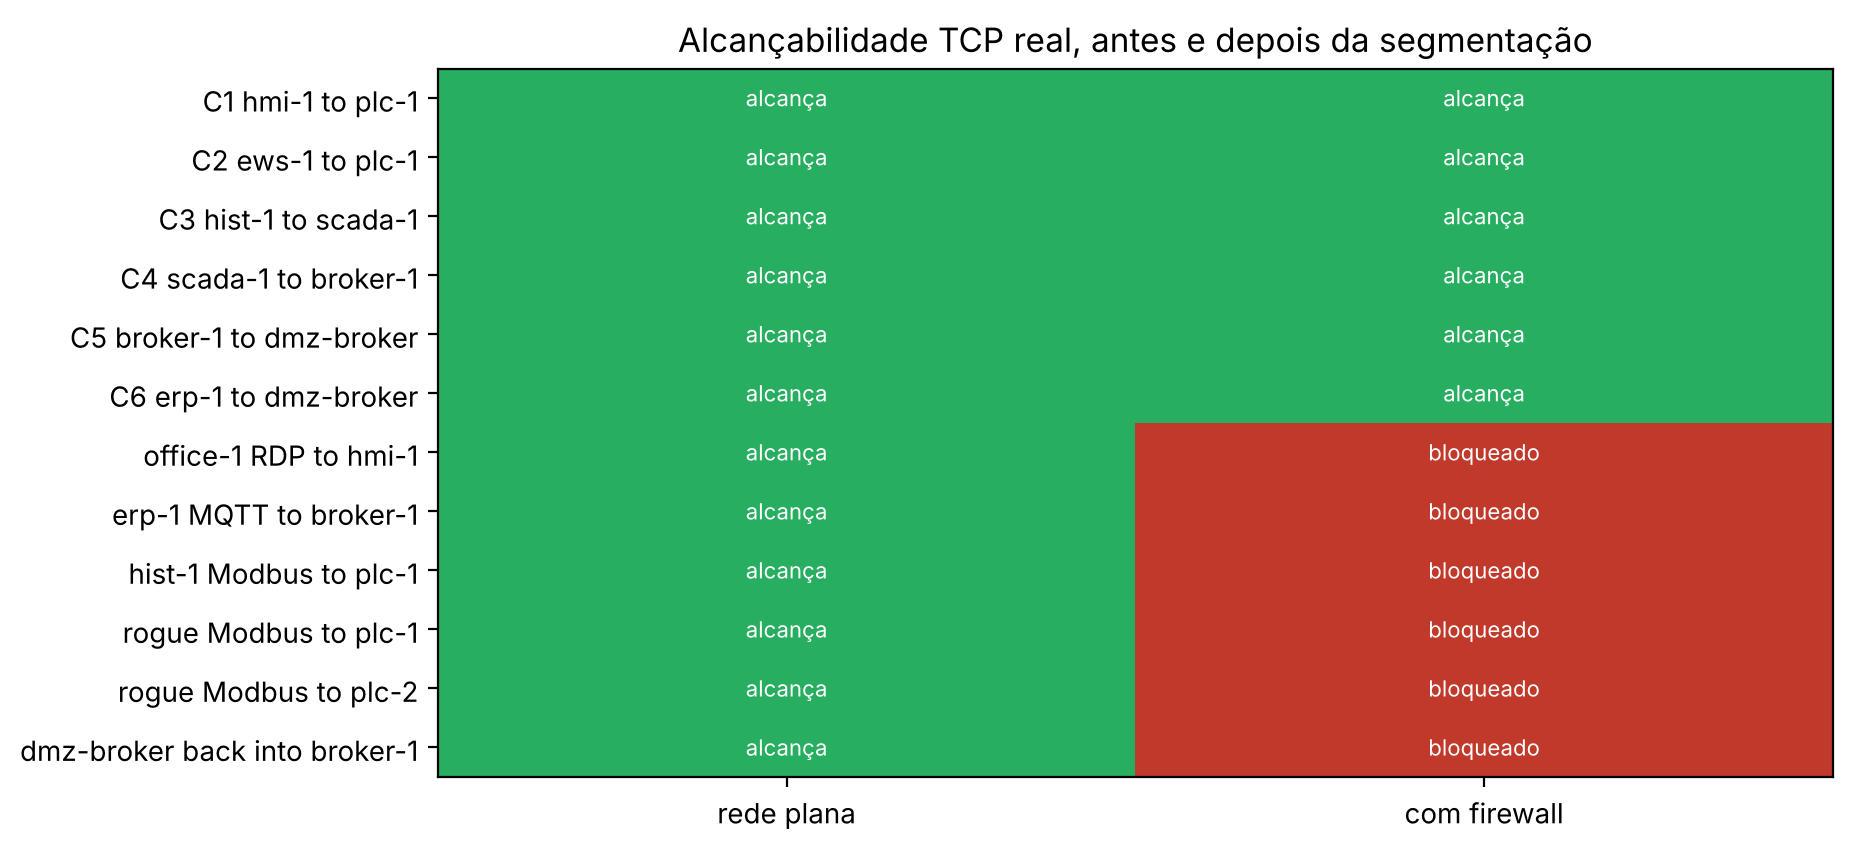

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.6))
import numpy as np
m = res[["antes", "depois"]].astype(int).values
ax.imshow(m, cmap=plt.matplotlib.colors.ListedColormap(["#c0392b", "#27ae60"]), aspect="auto")
ax.set_yticks(range(len(res)), res.caminho); ax.set_xticks([0, 1], ["rede plana", "com firewall"])
for i in range(len(res)):
    for j in range(2):
        ax.text(j, i, "alcança" if m[i, j] else "bloqueado", ha="center", va="center", color="white", fontsize=8)
ax.set_title("Alcançabilidade TCP real, antes e depois da segmentação")
from otsec import figures; figures.save(fig, "segmentation"); plt.show()

**Os seis conduítes continuam funcionando** e os seis caminhos indevidos foram fechados:

* o RDP do escritório para o HMI e o MQTT do ERP para a planta (TI chegando sem passar pela DMZ);
* o historiador lendo o CLP direto;
* o intruso tentando falar Modbus com os dois CLPs;
* a DMZ tentando voltar para dentro da planta. O conduíte C5 é de **saída**, a réplica nunca inicia conexão para o broker interno.

## 4. Os contadores do firewall

In [6]:
print(contadores)

Chain OTLAB (1 references)
 pkts bytes target     prot opt in     out     source               destination         
   24  1224 ACCEPT     0    --  *      *       0.0.0.0/0            0.0.0.0/0            ctstate RELATED,ESTABLISHED
    0     0 ACCEPT     0    --  *      *       127.0.10.0/24        127.0.10.0/24       
    0     0 ACCEPT     0    --  *      *       127.0.20.0/24        127.0.20.0/24       
    0     0 ACCEPT     0    --  *      *       127.0.30.0/24        127.0.30.0/24       
    0     0 ACCEPT     0    --  *      *       127.0.35.0/24        127.0.35.0/24       
    0     0 ACCEPT     0    --  *      *       127.0.40.0/24        127.0.40.0/24       
    1    60 ACCEPT     6    --  *      *       127.0.20.21          127.0.10.11          tcp dpt:502 /* C1 */
    0     0 ACCEPT     6    --  *      *       127.0.20.21          127.0.10.12          tcp dpt:502 /* C1 */
    0     0 ACCEPT     6    --  *      *       127.0.20.23          127.0.10.11          tcp dpt:502 /

Os contadores mostram quantos pacotes bateram em cada regra. Num firewall real, uma regra de conduíte com contador zero por meses é candidata a remoção, e um volume crescente na regra de REJECT é sinal para investigar.

## 5. E o Modbus? Por que ele precisa disso

Um servidor Modbus de verdade (pymodbus) aceita escrita de **qualquer** cliente que alcança a porta. Não há usuário, senha nem certificado no protocolo.

In [7]:
import asyncio, threading, time
from pymodbus.server import StartAsyncTcpServer, ServerAsyncStop
from pymodbus.datastore import ModbusSequentialDataBlock, ModbusSlaveContext, ModbusServerContext
from pymodbus.client import ModbusTcpClient
store = ModbusSlaveContext(hr=ModbusSequentialDataBlock(0, [0] * 200))
ctx = ModbusServerContext(slaves=store, single=True)
loop = asyncio.new_event_loop()
threading.Thread(target=lambda: loop.run_until_complete(StartAsyncTcpServer(ctx, address=("127.0.10.11", 502))), daemon=True).start()
time.sleep(1)

def escreve(origem, valor):
    c = ModbusTcpClient("127.0.10.11", port=502, source_address=(origem, 0), timeout=1)
    if not c.connect(): return "conexão recusada"
    r = c.write_register(100, valor); c.close()
    return f"escrita aceita, registrador 100 = {store.getValues(3, 100, 1)[0]}" if not r.isError() else str(r)

print("rede plana, intruso :", escreve("127.0.40.66", 9999))
seg.apply()
try:
    print("com firewall, intruso:", escreve("127.0.40.66", 7777))
    print("com firewall, EWS    :", escreve("127.0.20.22", 470))
finally:
    seg.remove()
asyncio.run_coroutine_threadsafe(ServerAsyncStop(), loop).result(5)

rede plana, intruso : escrita aceita, registrador 100 = 9999
com firewall, intruso: conexão recusada
com firewall, EWS    : escrita aceita, registrador 100 = 470


Na rede plana o intruso gravou **9999** no setpoint (técnica **T0836 Modify Parameter**). Com o firewall, a conexão dele nem abre, e a estação de engenharia continua gravando normalmente pelo conduíte C2. Para protocolos sem segurança nativa, **a segmentação é a autenticação**.

## Resumo

* O firewall é **gerado** do modelo de conduítes, com rastreabilidade regra a conduíte.
* Testes com conexões reais provam o que passa e o que não passa (`tests/test_segmentation.py`), antes e depois.
* Em produção, o mesmo modelo poderia gerar a configuração de um firewall industrial; o princípio é o mesmo.